In [1]:
import os
if 'COLAB_GPU' in os.environ:
  print("GPU")
else:
  print("not GPU")

GPU


In [2]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


In [3]:
!pip install -q ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 136.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.3 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO
import os
import yaml
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="46722j751UK6RIZnvTo7")
project = rf.workspace("skripsi-1qzlz").project("vehicle-detection-ckrxi")
version = project.version(2)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Vehicle-Detection-2 in yolov8:: 100%|██████████| 2012/2012 [00:00<00:00, 5786.19it/s]


In [7]:
data_yaml = os.path.join(
    dataset.location,
    "data.yaml"
)

with open(data_yaml, "r") as file:
    data_config = yaml.safe_load(file)

print(data_config)
print("Classes:", data_config["names"])
print("Number of classes:", data_config["nc"])

{'names': ['bus', 'car', 'motorbike', 'truck'], 'nc': 4, 'roboflow': {'license': 'CC BY 4.0', 'project': 'vehicle-detection-ckrxi', 'url': 'https://universe.roboflow.com/skripsi-1qzlz/vehicle-detection-ckrxi/dataset/2', 'version': 2, 'workspace': 'skripsi-1qzlz'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}
Classes: ['bus', 'car', 'motorbike', 'truck']
Number of classes: 4


In [10]:
model = YOLO("yolov8n.pt")

In [11]:
results = model.train(
    data=data_yaml,
    epochs=20,
    imgsz=640,
    batch=16,
    project="vehicle-detection-ckrxi",
    name="vehicle-detection",
    patience=10,
    plots=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Vehicle-Detection-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle-detection, nbs=64, nms=None, opset=None, op

In [12]:
!ls "/content/runs/detect/vehicle-detection-ckrxi/vehicle-detection/weights/"

best.pt  last.pt


In [13]:
!ls "/content/runs/detect/vehicle-detection-ckrxi/vehicle-detection/"

args.yaml			 results.csv	     val_batch0_labels.jpg
BoxF1_curve.png			 results.png	     val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg    val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg    val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg    val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch470.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch471.jpg  weights
labels.jpg			 train_batch472.jpg


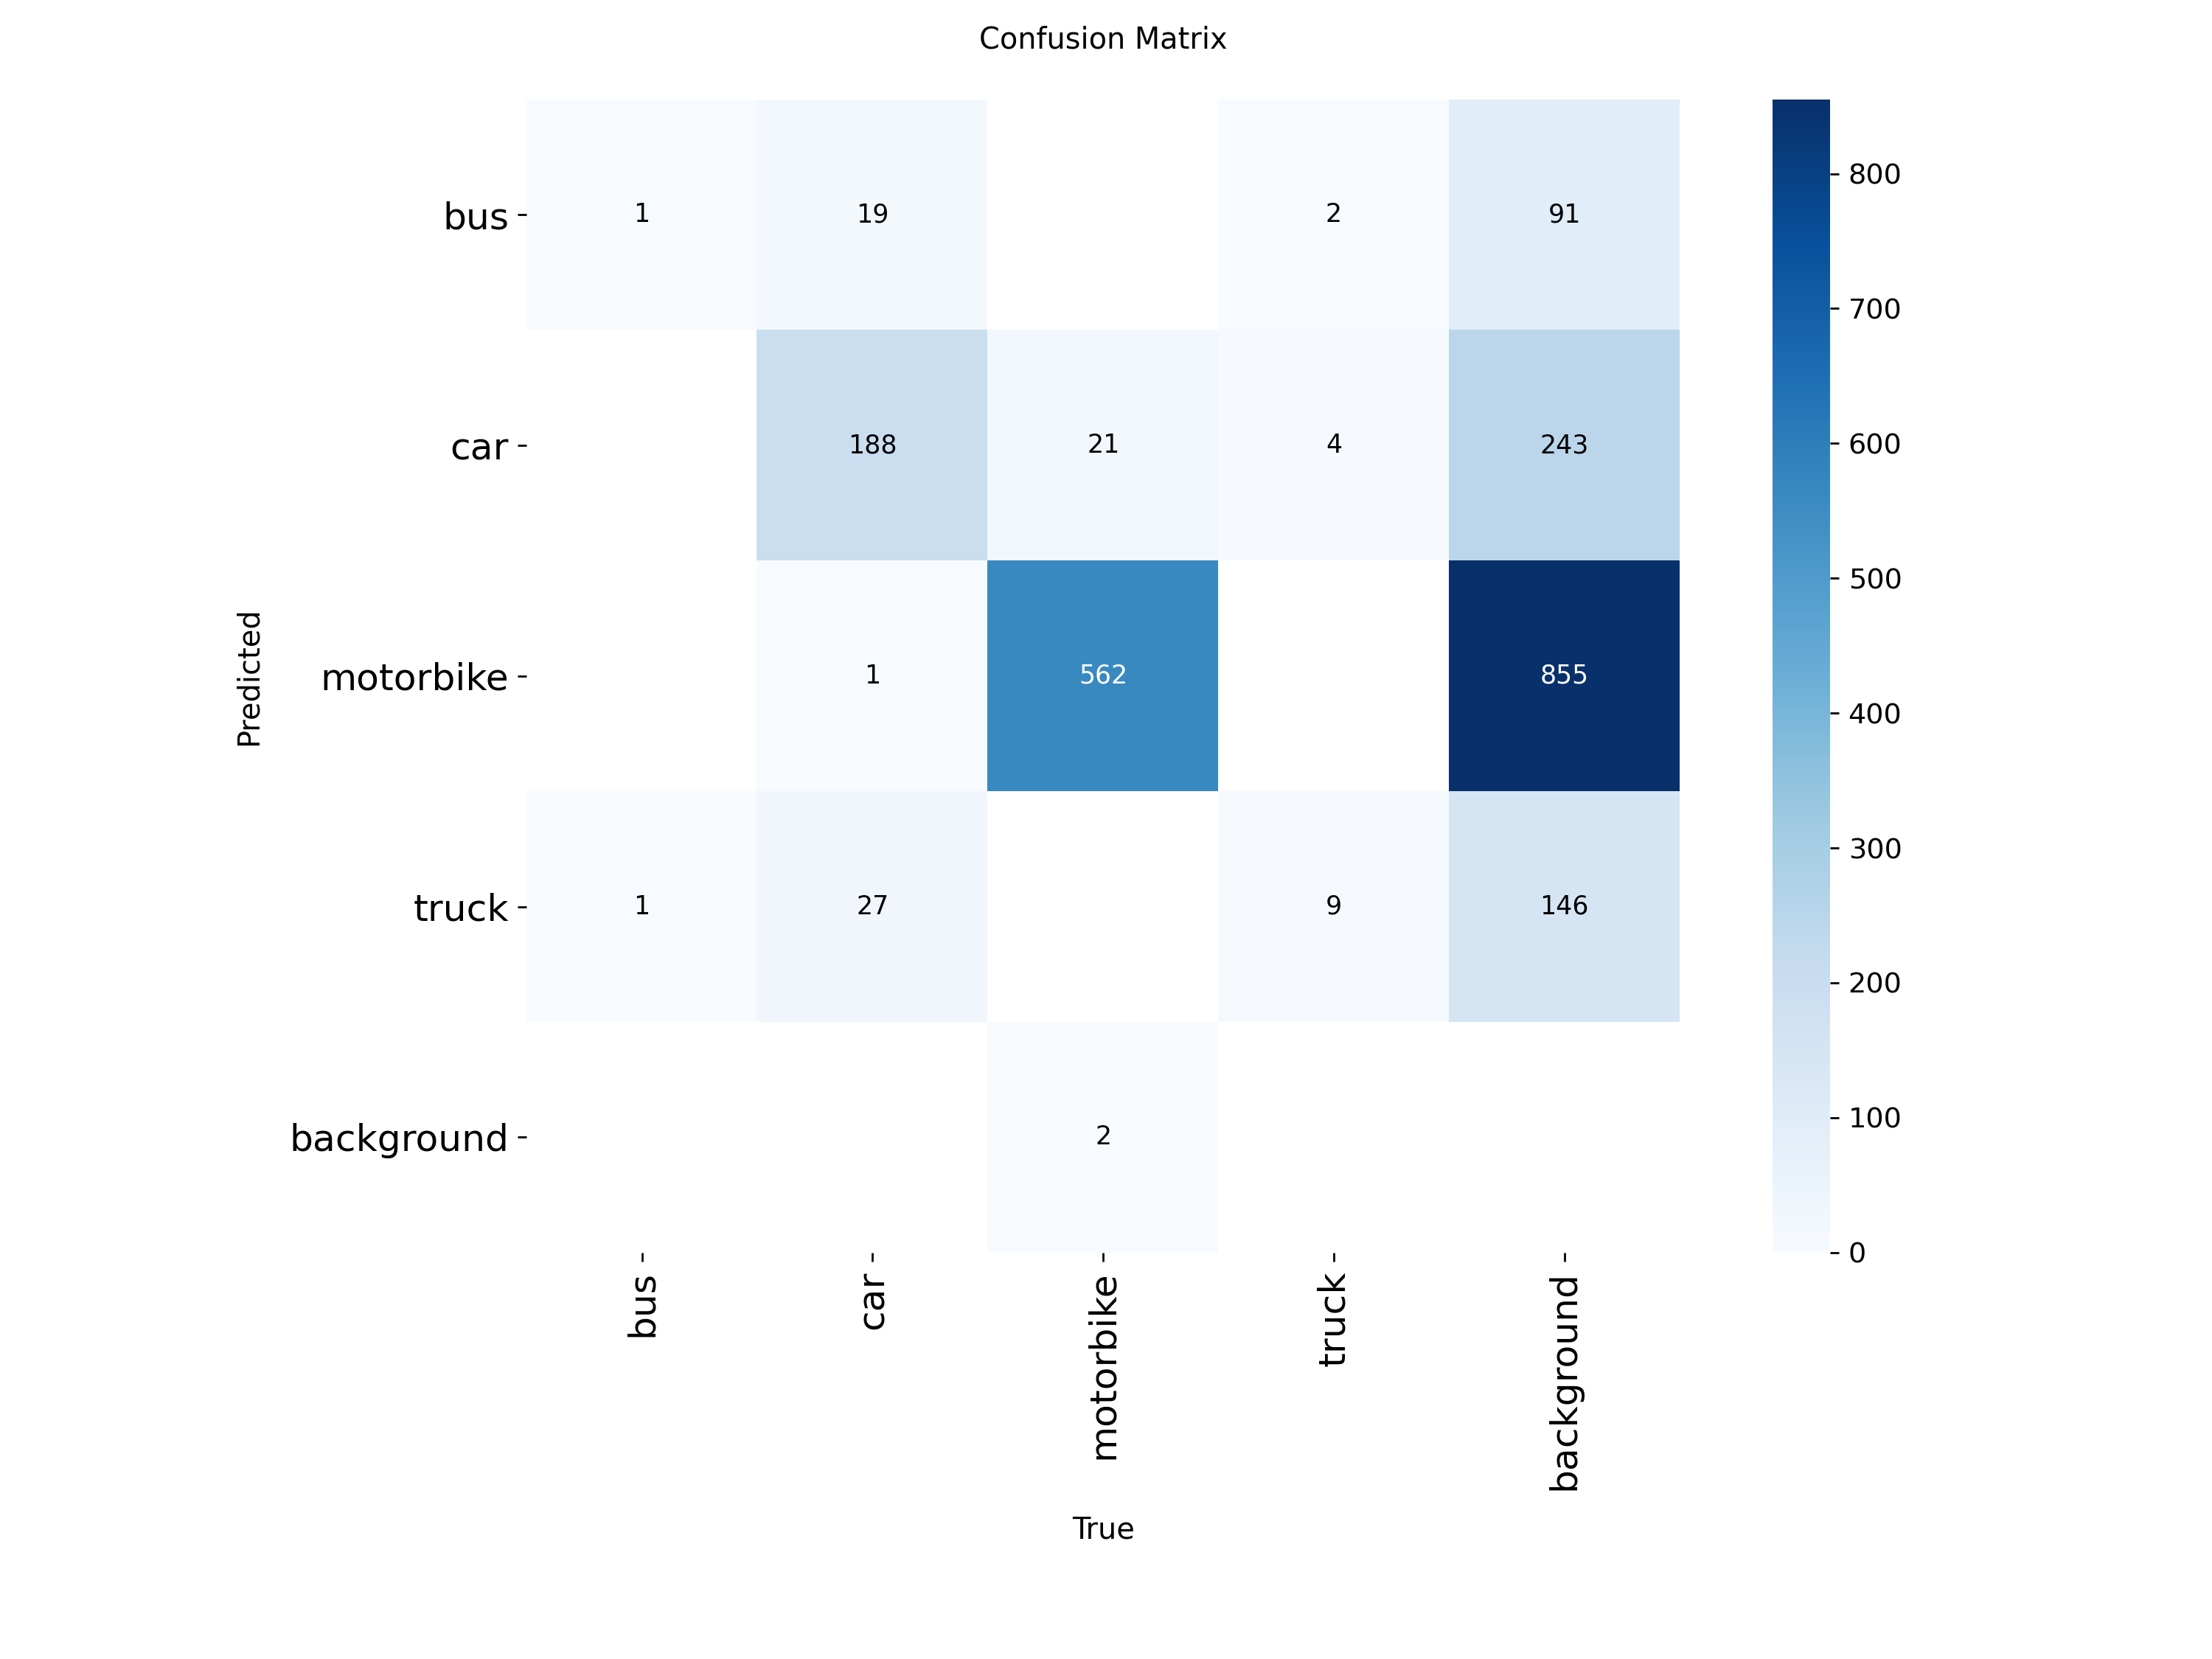

In [14]:
resultData = "/content/runs/detect/vehicle-detection-ckrxi/vehicle-detection/"

from IPython.display import Image, display

Image(filename = f"{resultData}confusion_matrix.png")

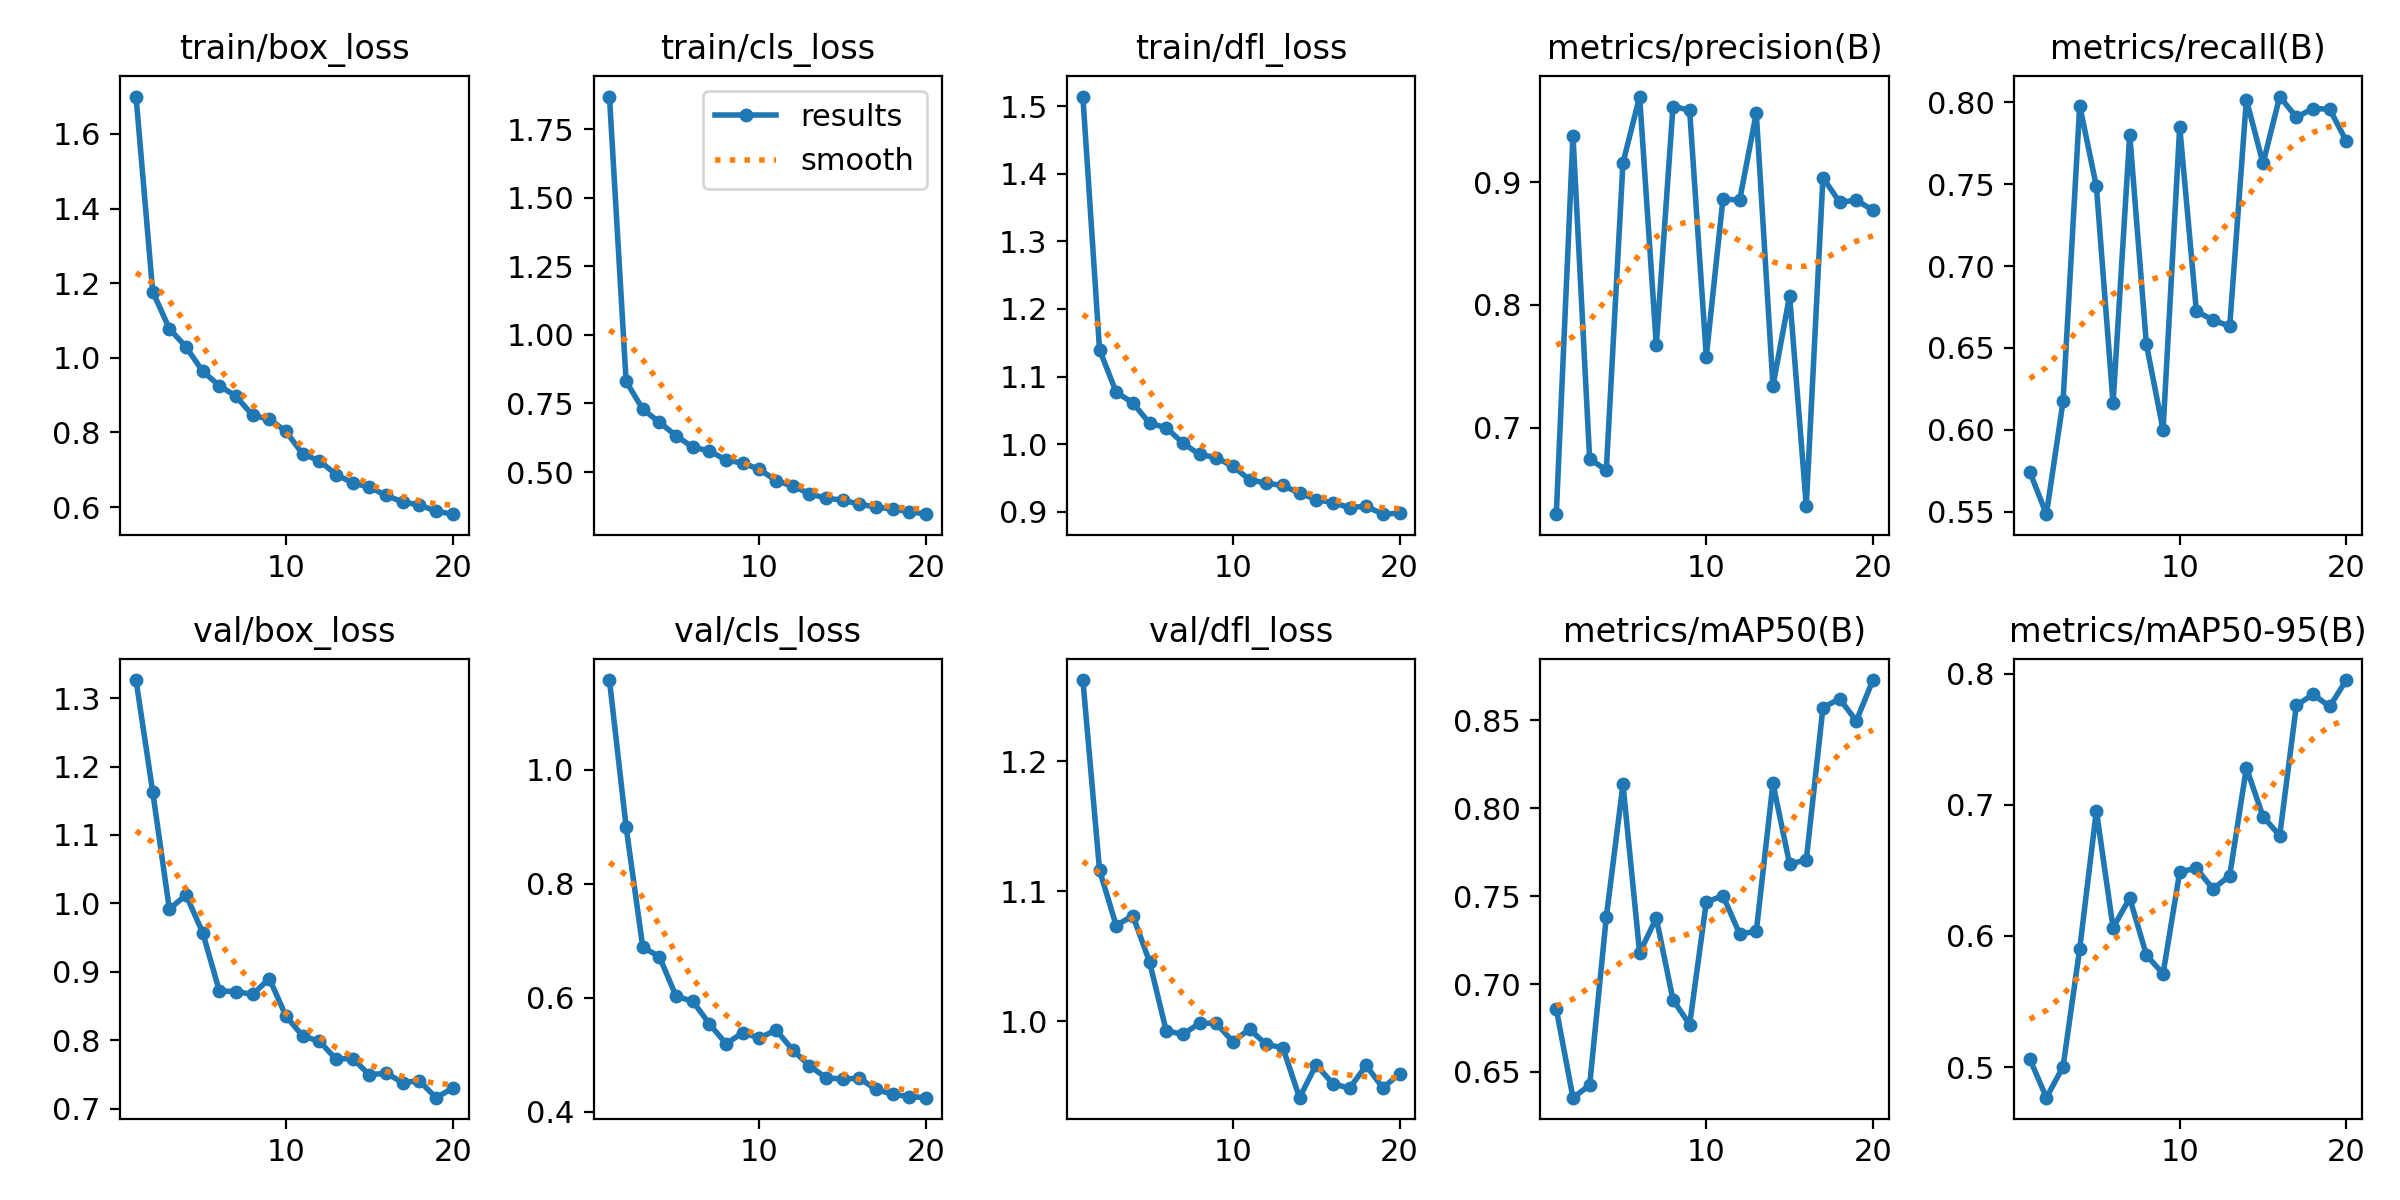

In [15]:
Image(filename = f"{resultData}results.png")

In [16]:
best_model = YOLO(
    "/content/runs/detect/vehicle-detection-ckrxi/vehicle-detection/weights/best.pt"
)

metrics = best_model.val(
    data=data_yaml,
    split="test",
    imgsz=640
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2169.5±686.4 MB/s, size: 82.1 KB)
val: Scanning /content/Vehicle-Detection-2/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.4Kit/s 0.1s
val: New cache created: /content/Vehicle-Detection-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.9it/s 5.4s
                   all        150       1518      0.972      0.917       0.97      0.858
                   bus         25         26      0.986      0.962      0.992      0.965
                   car        130        430      0.974      0.957      0.991      0.905
             motorbike        149       1032      0.988      0.916      0.991      0.832
                 truck         29         30      0.938      0

In [17]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

predictions = best_model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Prediction complete!")

Saving frame_109_jpg.rf.44d0500ab2e6b9470bedf0334f4a0354.jpg to frame_109_jpg.rf.44d0500ab2e6b9470bedf0334f4a0354.jpg

image 1/1 /content/frame_109_jpg.rf.44d0500ab2e6b9470bedf0334f4a0354.jpg: 640x640 4 cars, 11 motorbikes, 1 truck, 12.5ms
Speed: 1.1ms preprocess, 12.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction complete!


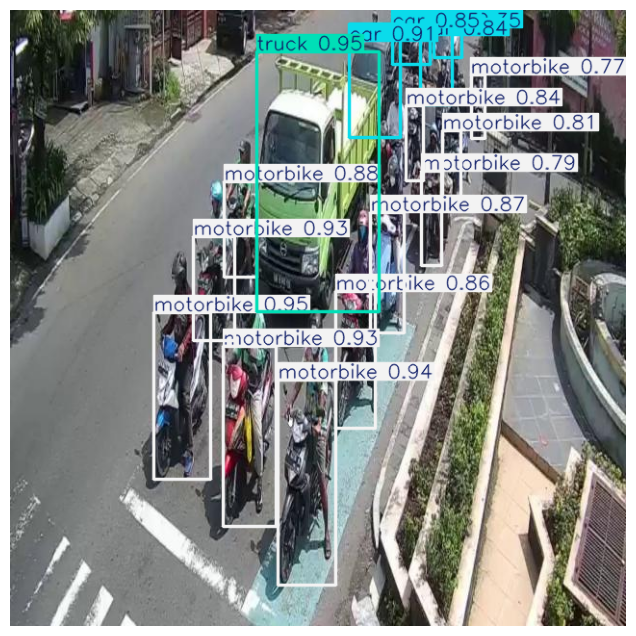

In [18]:
result_image = predictions[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(
    result_image[:, :, ::-1]
)
plt.axis("off")
plt.show()

In [20]:
import gradio as gr
from ultralytics import YOLO

# Apna trained model load karo
model = YOLO("/content/runs/detect/vehicle-detection-ckrxi/vehicle-detection/weights/best.pt")

# Prediction function
def detect_objects(image):
    results = model.predict(image, conf=0.25)
    output_image = results[0].plot()
    return output_image

# Gradio interface
demo = gr.Interface(
    fn=detect_objects,
    inputs=gr.Image(type="pil", label="Upload Road Image"),
    outputs=gr.Image(type="numpy", label="Detection Result"),
    title="Road Traffic Detection",
    description="Upload a road image to detect traffic objects."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://df5ebbed19cb581b58.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
